# KQC SingleXmons — six Swissmons on one feedline (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/single_xmons.py` (class `SingleXmons`; © 2021 IQM Finland Oy, GPL-3.0,
<https://github.com/iqm-finland/KQCircuits>; local copy `other-libs/KQCircuits-main/.../kqcircuits/chips/single_xmons.py`).
Six Swissmon qubits, three above and three below a horizontal feedline from launcher WN to launcher ES of an
SMA8 sample holder. Each qubit has a λ/4 readout resonator (5000 … 5500 µm) coupled to the feedline over a
450 µm hanger section, and a charge line from its own launcher. Four test resonators (5200 … 5800 µm) hang off
the feedline through finger / gap capacitors on T-splitters, and four junction test-pad arrays sit on the chip
edges.

This notebook **rebuilds** the chip with our components, routes, netlist and LOM on the Quantcore PDK (not a
replica); we distribute the rebuild under GPL-3.0.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm (SMA8 launchers on its edges), Quantcore die frame, device ID "SXMONS" |
| launchers | SMA8, `launcher_indent` 800 µm (outer etch 20 µm from the edge) | SMA8, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm, 80 µm further in than KQC's) |
| substrate | silicon εr 11.45 (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junctions | KQC Manhattan SQUIDs (assumed L_J 16 nH) | Quantcore trilayer SQUIDs, 2 × 0.25 × 0.6 µm, R_n 45 kΩ in parallel, L_J 6.73 nH |
| cheese | KQC's whole-area ground grid (`with_grid`) | **the original wins:** KQC's grid (`with_grid=True`), no PDK band |
| readout couplers | 400 µm straight + bend, 27 µm from the feedline centre (5 µm ground strip) | same centres, now given as `near=(x, y)` points on the feedline (they no longer slide when the launchers move) |
| placement | centred | centred (no shift) |

**Kept exactly:** the six `Swissmon`s (arm 146 µm, coupler 1 of 140 µm, no flux line, charge-line offset
200 µm) at the KQC positions and rotations; the feedline path WN → (2000, y_WN) → (2000, 5000) → (8000, 5000) →
(8000, y_ES) → ES; the four tees and capacitors (`cap_params(4, 23.1)`, `(4, 9.9)`, `(2, 14.1)` interdigital and
`(4, 10)` gap); the test-resonator paths and lengths; the charge lines with their 6 µm open end; the four
`JunctionTestPads` arrays; the readout lengths and the 27 µm coupling.

**Simplified:** each readout is a qcc *hanger* route: qubit → meander → 450 µm coupler → shorted end (KQC puts
the meander after the coupler); same λ/4 topology and length, slightly different footprint. The test-resonator
meanders are fitted by the router instead of KQC's fixed 250 µm-wide `Meander`.

**Fixed here:** the pad rule moves the launchers in (80 µm with today's 100 µm rule), and KQC's hard-coded
arclengths (`s = x + 1400` along the first feedline segment) would slide RR3's coupler with them (an earlier, smaller launcher shift already left a 5 µm segment the router could not bend). The couplers are now anchored by position
(`near=`) and the feedline's corners by the launcher ports, so they stay at KQC's positions whatever the indent.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die with its eight SMA8 launchers, the launchers and the pad rule, the feedline with its four tees and the four test resonators, the six Swissmons and the four junction-test arrays, the six λ/4 readouts, the charge lines, and then the whole chip (the sim groups, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `singlexmons.v1.ipynb`; both save the same `singlexmons.json`.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/singlexmons/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")
STEPS = Path("build/snapshots/singlexmons")      # step-by-step snapshots (not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The stack feeds the LOM estimates and FEM exports, the frame and pad rule shape the die, the junction rule sizes
the SQUIDs, the cheese / 3/0 / rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand: the die and its launchers, the readout line, the qubits,
their readout resonators, the control lines, and then the whole chip. Each segment is one cell with one picture of
the chip so far (live, KLayout redraws after every cell). A route joins two ports, or a port and a hanger on another
route, so the feedline comes before the readouts that hang on it. KQC's ground grid (`with_grid`, ≈ 0.8 M holes) is drawn in every build, so each picture rebuilds the whole chip:
the pictures stay at the v1's size, one per segment.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame and the SMA8 sample holder's eight launchers |
| 2 | the launchers and the pad rule (they come with the die: a look and a table) |
| 3 | the readout line: the feedline WN → ES through four tees, and on the tees the four test capacitors with their λ/4 test resonators (no qubit needed) |
| 4 | the qubits: six Swissmons with their trilayer SQUIDs, and the four junction-test arrays on the edges |
| 5 | the readout resonators: six λ/4 hangers, qubit coupler → meander → 450 µm coupler along the feedline |
| 6 | the coupling: none (the qubits share only the feedline) |
| 7 | the control routing: six charge lines |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die, its frame and the launchers

10 × 10 mm with the SMA8 sample holder's eight launchers (NW, NE, EN, ES, SE, SW, WS, WN), the chip name
"SXMONS" as device ID, and KQC's whole-area ground grid (`with_grid=True`: the original's cheese, so the PDK band
is not added). The Quantcore frame (dicing L's, alignment grids, boundary) replaces KQC's ChipFrame.

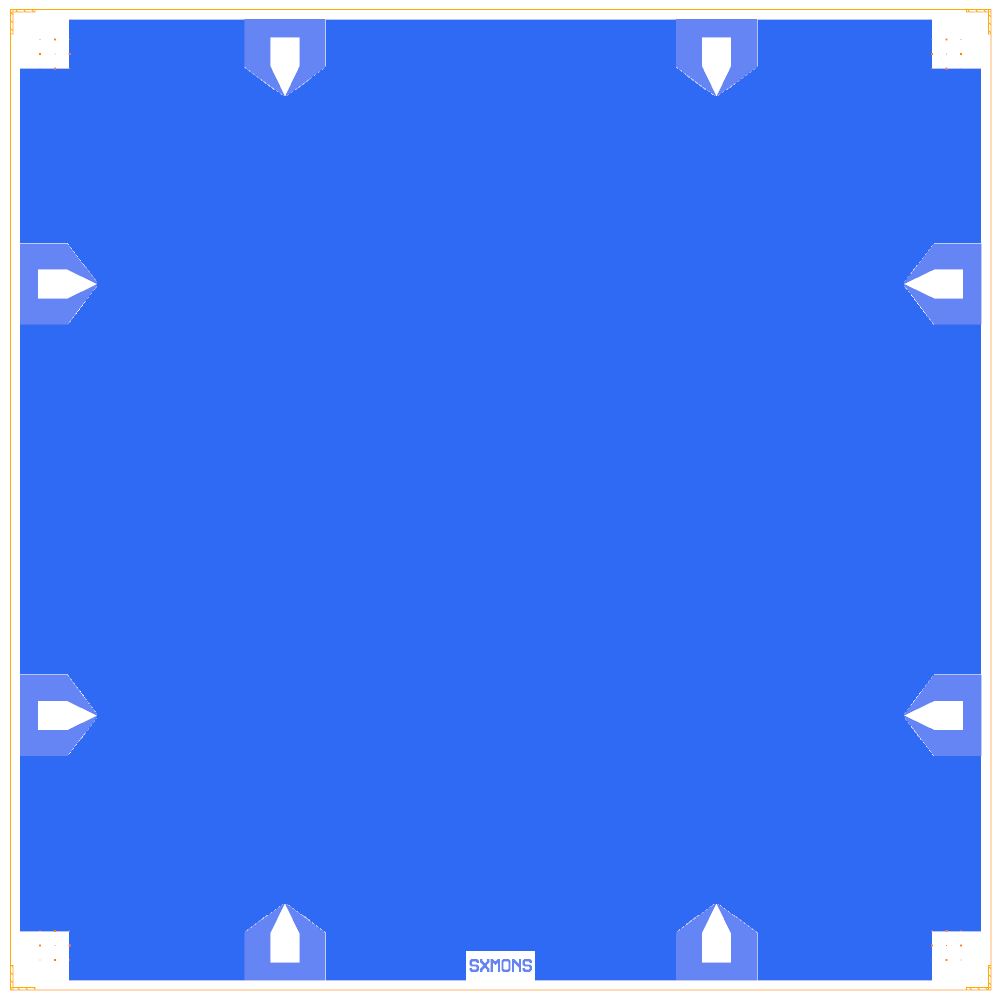

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout. The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the pad count stays 0.

WindowsPath('build/snapshots/singlexmons/1_die.png')

In [5]:
d = Designer("singlexmons", box=(0, 0, 10000, 10000), launchers="SMA8",
             chip={"name_chip": "SXMONS", "with_grid": True}, live=LIVE)
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "1_die.png", **CHIP,
            note="The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the "
                 "pad count stays 0.")

## Design 2 · Bond pads: the launchers and the pad rule

The PDK puts a launcher's outer etch edge `frame.pad_edge` (100 µm) from the die edge: for SMA8 (RF launcher, 300 µm taper + 300 µm
pad + 180 µm frame gap) the Designer sets `launcher_indent` = 100 + 300 + 300 + 180 = **880 µm** (KQC: 800). Every
route that starts at a launcher takes its waypoints from the launcher's port (`port_xy(d, "chip.WN")`), so the
80 µm shift needs no other change.

The launchers came with the die (Design 1): nothing is added here. The table measures them, the picture zooms on WN.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.NW | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.NE | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.EN | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.ES | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.SE | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.SW | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.WS | launcher port | w | port 880 µm in (indent from the rule) | ✓ |
| chip.WN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

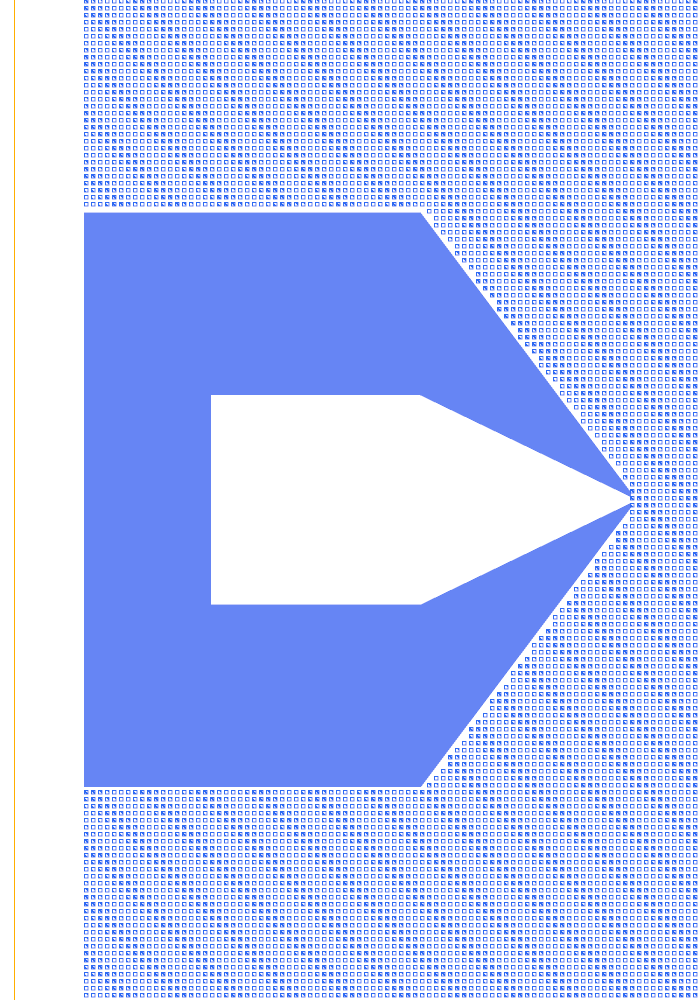

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, "chip.WN")
snap(d, STEPS / "2_launcher.png", box=(-20, y - 400, x + 100, y + 400), size=(700, 1000), width=300);

## Design 3 · Readout: the feedline, its tees and the test resonators

**Feedline tees and test capacitors.** Four `WaveguideCoplanarSplitter` tees on the feedline (y = 5000), each
with a `FingerCapacitorSquare` snapped to its bottom port: interdigital `cap_params(4, 23.1)`, `(4, 9.9)`,
`(2, 14.1)` and a gap capacitor `(4, 10)` — KQC's `cap_params`.

**Feedline** WN → T0 → T1 → T2 → T3 → ES in five CPW routes (KQC joins the tees right / left alternately). Its
two corners take their y from the launcher ports.

**Test resonators** from each capacitor: 300 µm out, 500 µm sideways, 100 µm, then a meander as tall as KQC's
250 µm-wide one, ending short (`d.free_end(..., term=0)`); bend radius 50 µm.

The tees sit between the qubits' x positions (`tee_x` comes from KQC's qubit grid `qpos`, numbers only: the qubits
themselves are placed in Design 4), so the whole feedline comes first. The test resonators hang on the tees and need
no qubit, so they come with it.

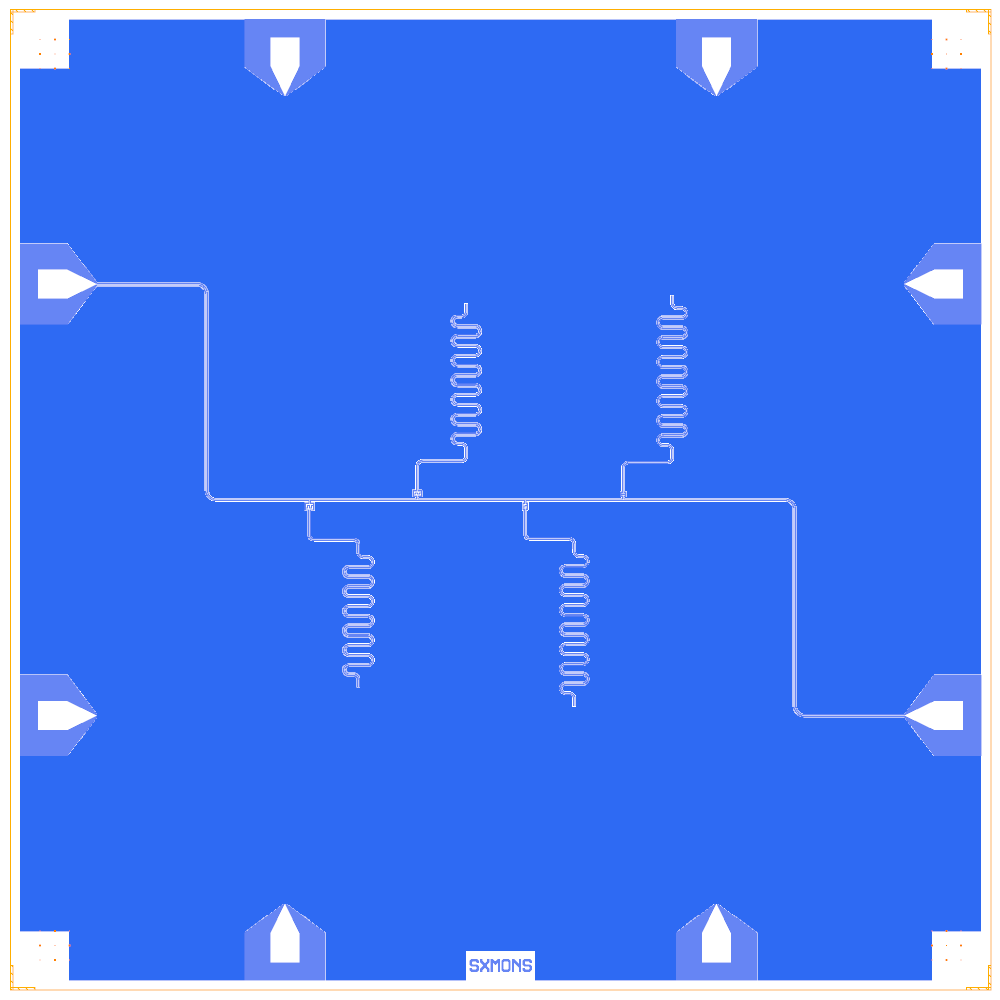

**On the chip so far:** 0 pads · 0 qubits · 8 other components · 9 routes · 0 declared couplings. **This step added** 8 component(s) `T0`, `T1`, `T2`, `T3`, `C0`, `C1`, `C2`, `C3` and 9 route(s) `FL0`, `FL1`, `FL2`, `FL3`, `FL4`, `TR0`, `TR1`, `TR2` … (+1).

WindowsPath('build/snapshots/singlexmons/s3_feedline.png')

In [7]:
cx, sx, sy = 5400, 1100, 2600                    # KQC's qubit grid (the qubits are placed in Design 4)
qpos = {"QB0": (cx - 1.5 * sx, 5000 + sy / 2, 180), "QB1": (cx + 0.5 * sx, 5000 + sy / 2, 180),
        "QB2": (cx + 2.5 * sx - 200, 5000 + sy / 2, 180), "QB3": (cx - 2.5 * sx, 5000 - sy / 2, 0),
        "QB4": (cx - 0.5 * sx, 5000 - sy / 2, 0), "QB5": (cx + 1.5 * sx, 5000 - sy / 2, 0)}
tee_x = [(qpos["QB3"][0] + qpos["QB4"][0]) / 2 - 700, (qpos["QB1"][0] + qpos["QB0"][0]) / 2 - 700,
         (qpos["QB5"][0] + qpos["QB4"][0]) / 2 - 700, (qpos["QB2"][0] + qpos["QB1"][0]) / 2 - 700]
caps = [dict(finger_number=4, finger_length=23.1, finger_gap_end=5, finger_gap=5, finger_width=15),
        dict(finger_number=4, finger_length=9.9, finger_gap_end=5, finger_gap=5, finger_width=15),
        dict(finger_number=2, finger_length=14.1, finger_gap_end=5, finger_gap=5, finger_width=15),
        dict(finger_number=4, finger_length=0, finger_gap_end=10, finger_gap=0, finger_width=10)]  # "gap"
_, y_wn = port_xy(d, "chip.WN")
_, y_es = port_xy(d, "chip.ES")
with d.batch():
    tee = [d.add(f"T{i}", "WaveguideCoplanarSplitter", at=(x, 5000), rot=180 * (i % 2), lengths=[11, 11, 31],
                 port_names=["right", "left", "bottom"]) for i, x in enumerate(tee_x)]
    cap = [d.add(f"C{i}", "FingerCapacitorSquare", snap="b", to=tee[i].bottom, ground_padding=10, **caps[i])
           for i in range(4)]
    d.route("FL0", "chip.WN", tee[0].left, nodes=[(2000, y_wn), (2000, 5000)])
    d.route("FL1", tee[0].right, tee[1].right)
    d.route("FL2", tee[1].left, tee[2].left)
    d.route("FL3", tee[2].right, tee[3].right)
    d.route("FL4", tee[3].left, "chip.ES", nodes=[(8000, 5000), (8000, y_es)])
    for i, length in enumerate([5200, 5400, 5600, 5800]):
        f = 2 * (i % 2) - 1                                   # -1: below the feedline, +1: above
        x, y = port_xy(d, f"C{i}.a")
        h = 2 * 50 * (kqc_meanders(length - 857, 50, 250) + 1)  # 857 µm: the non-meander part with its two bends
        d.route(f"TR{i}", cap[i].a, d.free_end((x + 500, y + f * (400 + h)), dir=-90 * f, term=0),
                nodes=[(x, y + f * 300), (x + 500, y + f * 300), (x + 500, y + f * 400)], meander=length, r=50)
layout_step(d, STEPS / "s3_feedline.png", **CHIP)

## Design 4 · Qubit placement: six Swissmons and the junction-test arrays

**The junction.** KQC draws a SQUID in every Swissmon; `trilayer_junction` makes it the Quantcore trilayer SQUID
at the PDK nominal L_J (two 0.25 × 0.6 µm junctions, 45 kΩ in parallel). KQC's `junction_width` carries the
straight finger; `JUNCTION` (L_J, C_J) goes to the LOM and the FEM junction ports.

**Qubits.** Six `Swissmon`s: QB0–QB2 above the feedline (rotated 180°), QB3–QB5 below; arms 146 µm wide 24 µm,
gap 24 µm, only coupler 1 (140 µm long, 24 µm wide, 102 µm gap) towards the feedline, no flux line, charge-line
offset 200 µm. Ports: `cplr0`–`cplr2`, `drive` (plus `flux`, unused here).

**Junction test arrays** (KQC `Chip.produce_junction_tests`): four `JunctionTestPads` areas on the edges, with
the same trilayer SQUID.

The first picture is the chip so far, the second zooms on QB0 (no rebuild: the same build).

In [8]:
LJ_PDK = trilayer_junction("Swissmon")[1]["Lj_nH"]          # PDK nominal L_J (0.5 × 0.6 µm junction, R_n 45 kΩ)
JJ_PARAMS, JUNCTION = trilayer_junction("Swissmon", lj_nH=LJ_PDK, squid=True)
print("cell parameters:", JJ_PARAMS, "| LOM junction:", JUNCTION)

cell parameters: {'junction_type': 'Quantcore Squid', 'junction_width': 0.25} | LOM junction: {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


<Swissmon QB0 ports=['cplr0', 'cplr1', 'cplr2', 'drive']>


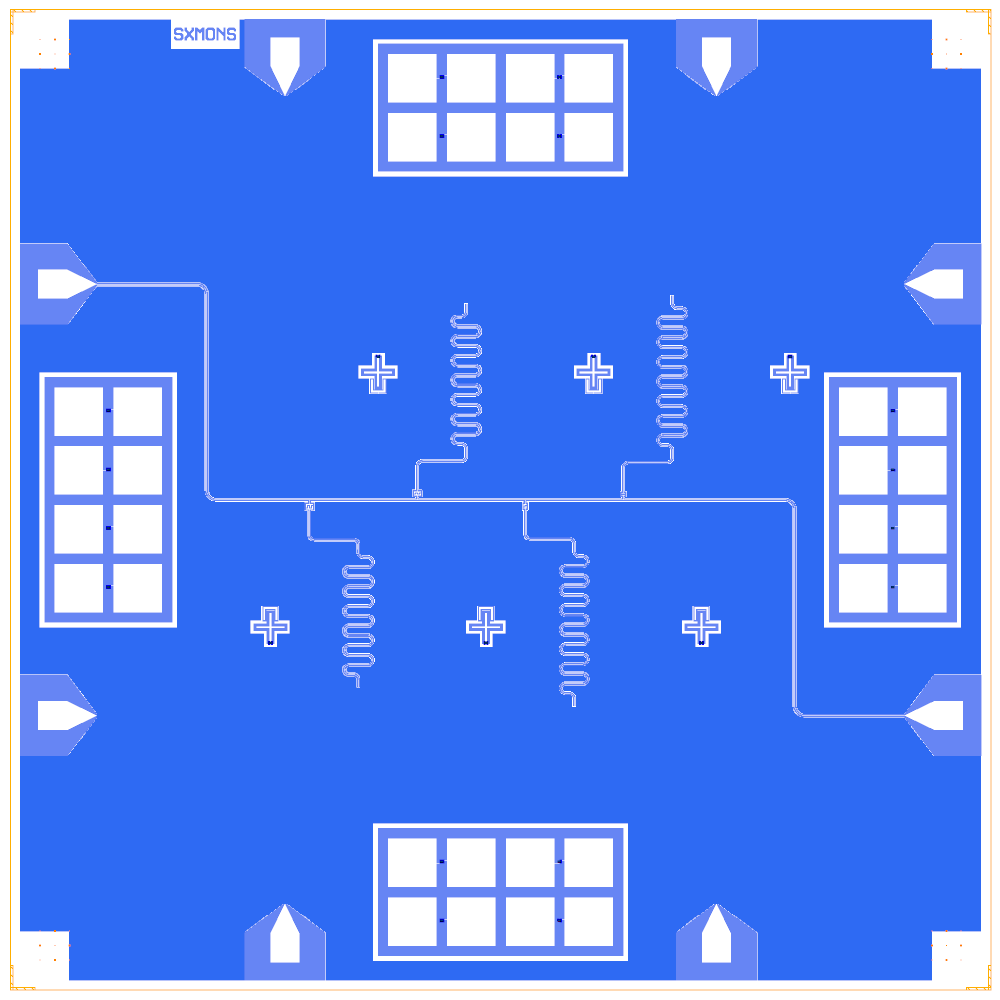

**On the chip so far:** 0 pads · 0 qubits · 18 other components · 9 routes · 0 declared couplings. **This step added** 10 component(s) `JT_W`, `JT_S`, `JT_E`, `JT_N`, `QB0`, `QB1`, `QB2`, `QB3` … (+2). KQC's qubit cells carry no Quantcore qubit category yet, so this line counts them among the other components.

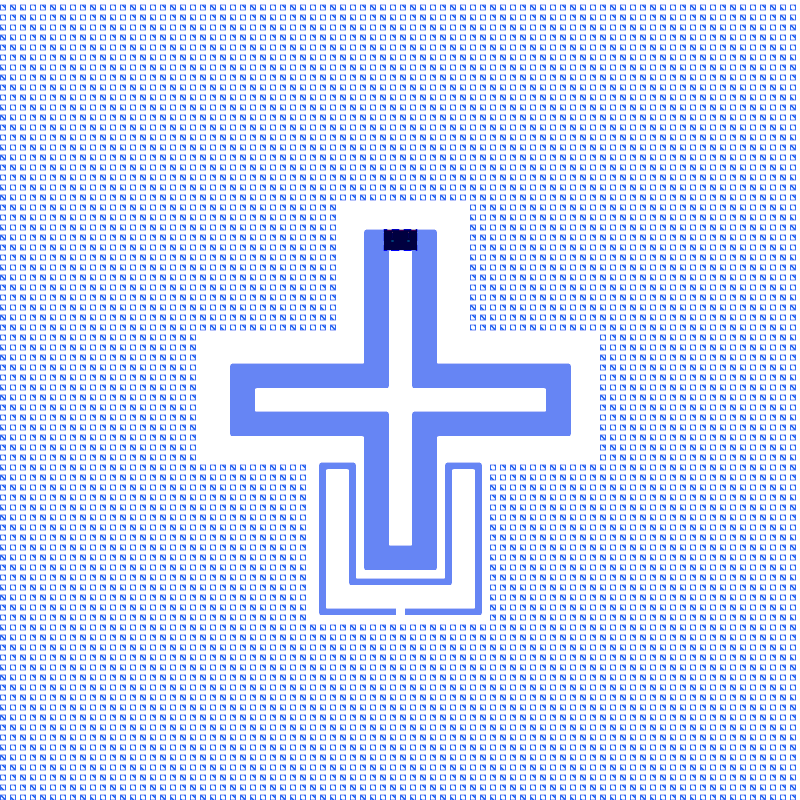

In [9]:
with d.batch():
    JTP = "kqcircuits.test_structures.junction_test_pads.junction_test_pads.JunctionTestPads"
    for name, at, (w, h) in (("JT_W", (350, 3750), (1300, 2500)), ("JT_S", (3750, 350), (2500, 1300)),
                             ("JT_E", (8350, 3750), (1300, 2500)), ("JT_N", (3750, 8350), (2500, 1300))):
        d.add(name, JTP, at=at, margin=50, area_width=w, area_height=h, junctions_horizontal=True, **JJ_PARAMS)

    swissmon = dict(fluxline_type="none", arm_length=[146] * 4, arm_width=[24] * 4, gap_width=[24] * 4, island_r=2,
                    cpl_length=[0, 140, 0], cpl_width=[60, 24, 60], cpl_gap=[110, 102, 110], cl_offset=[200, 200])
    qb = {n: d.add(n, "Swissmon", at=(x, y), rot=r, junction=JUNCTION, **JJ_PARAMS, **swissmon)
          for n, (x, y, r) in qpos.items()}
print(qb["QB0"])
layout_step(d, STEPS / "s4_qubits.png", **CHIP,
            note="KQC's qubit cells carry no Quantcore qubit category yet, so this line counts them among "
                 "the other components.")
x0, y0, _ = qpos["QB0"]
snap(d, STEPS / "s4_qb0.png", box=(x0 - 400, y0 - 400, x0 + 400, y0 + 400), size=(800, 800), width=320);

## Design 5 · Readout: the six λ/4 hangers

**Readout resonators** (λ/4): coupler 1 → meander → a 450 µm hanger coupler along the feedline, 27 µm from its
centre (5 µm ground strip between the two CPWs) → shorted end. `FL.hanger(near=(x, y), ...)` centres the coupler
at the feedline point nearest (x, y): here 225 µm towards −x from the qubit, on whichever feedline segment
passes there — KQC's positions, independent of where the feedline starts. `direction="backward"` puts the
shorted end towards the feedline's start. `meander=` makes each readout that long: the router puts what the hanger and the bends leave over into
one KQC `Meander`, with no more turns than keep it at least one bend radius wide.

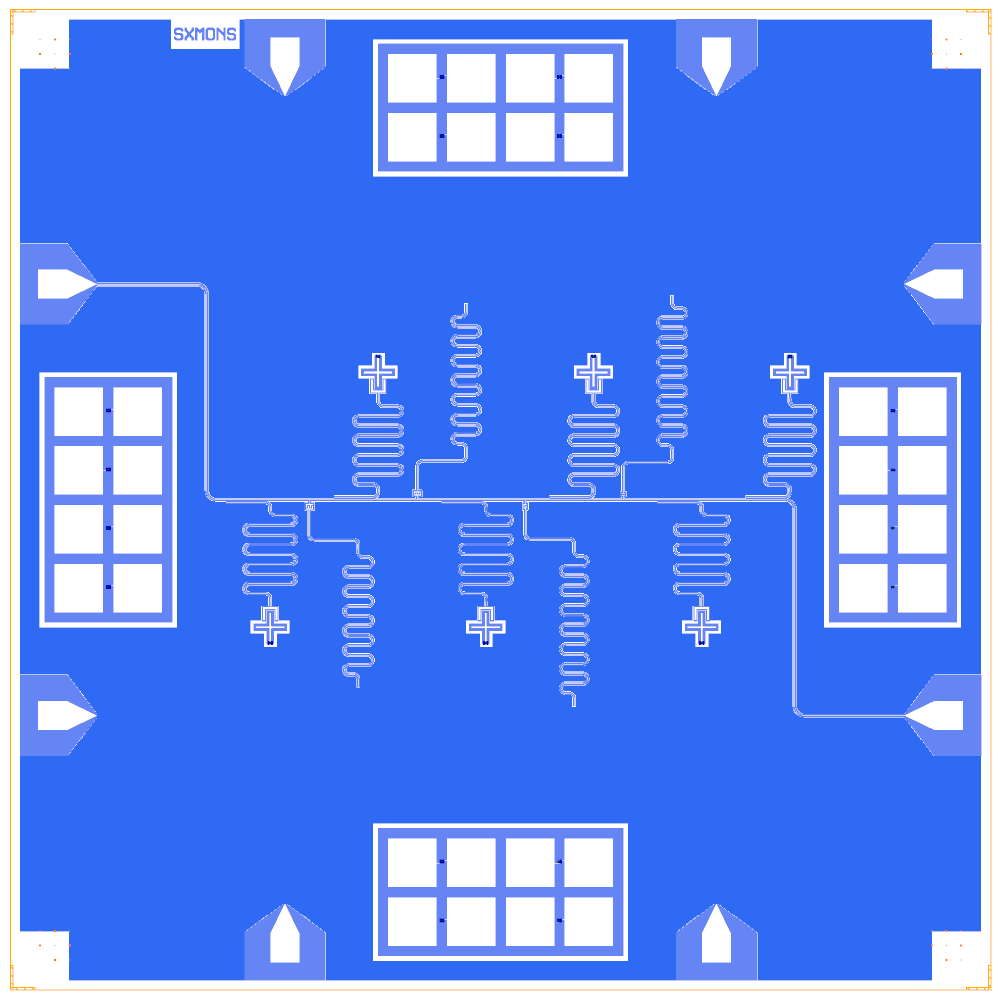

**On the chip so far:** 0 pads · 0 qubits · 18 other components · 15 routes · 0 declared couplings. **This step added** 6 route(s) `RR0`, `RR1`, `RR2`, `RR3`, `RR4`, `RR5`.

WindowsPath('build/snapshots/singlexmons/s5_readouts.png')

In [10]:
with d.batch():
    for i, (n, (x, y, r)) in enumerate(qpos.items()):
        xc = x - 225                                          # coupler centre: from the qubit's x towards -x
        seg = next(f"FL{k}" for k, t in enumerate(tee_x + [1e9]) if xc < t)
        d.route(f"RR{i}", qb[n].cplr1, d[seg].hanger(near=(xc, 5000), length=450, side="left" if r else "right",
                                                    ground_gap=5, direction="backward"), meander=5000 + 100 * i, r=50)
layout_step(d, STEPS / "s5_readouts.png", **CHIP)

## Design 6 · Coupling: none

The six qubit–readout pairs share only the feedline; no bus or coupler joins the qubits (they sit 1.1 mm apart), so
there is nothing to add here.

## Design 7 · Routing: the charge lines

**Charge lines** from each qubit's launcher, ending 6 µm short of the drive port (`term2=6`); their corners
take the launcher port's y.

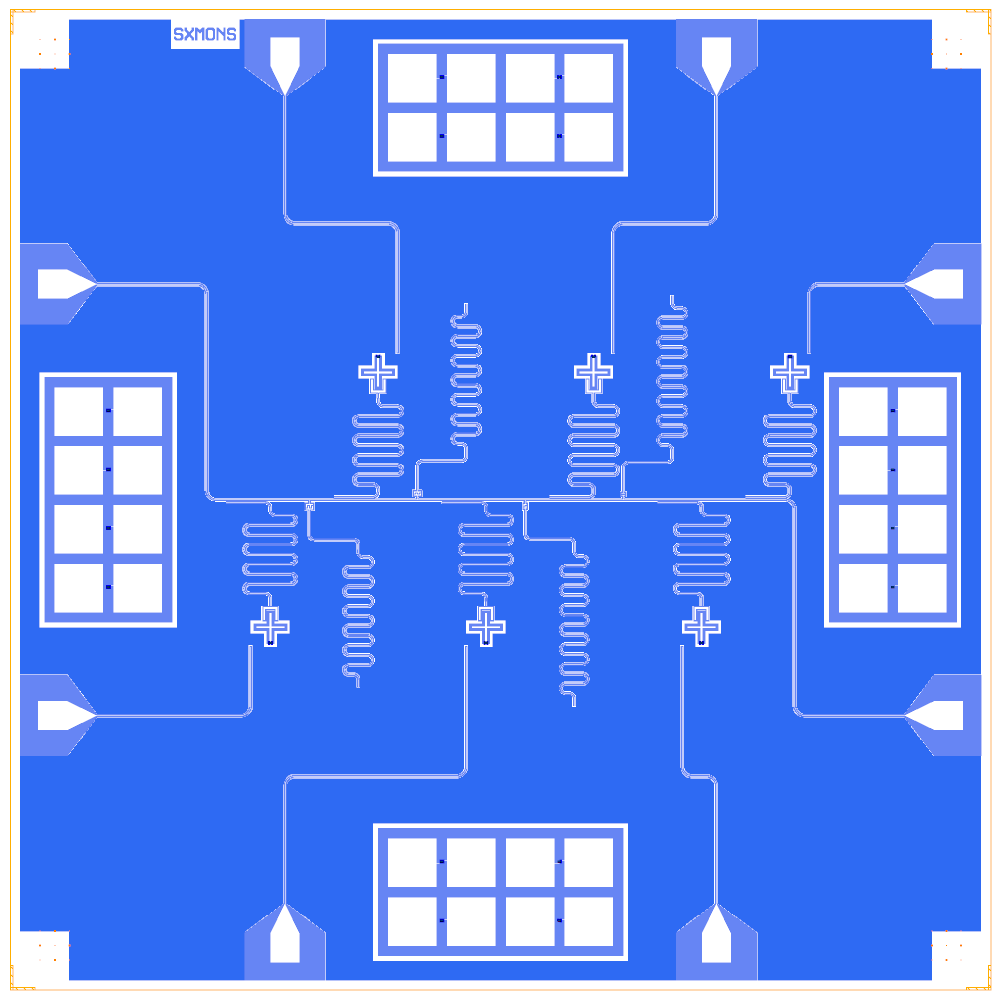

**On the chip so far:** 0 pads · 0 qubits · 18 other components · 21 routes · 0 declared couplings. **This step added** 6 route(s) `CL0`, `CL1`, `CL2`, `CL3`, `CL4`, `CL5`.

WindowsPath('build/snapshots/singlexmons/s7_charge_lines.png')

In [11]:
with d.batch():
    for i, (launcher, n, dy) in enumerate((("NW", "QB0", -1300), ("NE", "QB1", -1300), ("EN", "QB2", 0),
                                           ("WS", "QB3", 0), ("SW", "QB4", 1300), ("SE", "QB5", 1300))):
        (lx, ly), (px, py) = port_xy(d, f"chip.{launcher}"), port_xy(d, f"{n}.drive")
        d.route(f"CL{i}", f"chip.{launcher}", qb[n].drive,
                nodes=[(lx, ly + dy), (px, ly + dy)] if dy else [(px, ly)], term2=6)
layout_step(d, STEPS / "s7_charge_lines.png", **CHIP)

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups, centring, save.** One sim group per qubit with its readout (Q3D C-matrix + eigenmode/EPR, 300 µm
margin). `center_in_die` confirms the content is centred (no shift); `singlexmons.json` is then saved with `save_design`,
which compares it with the file it replaces (the previous run's): the segments above changed how the chip is built
(the feedline and test resonators before the qubits), not the chip, so it should say *same design*; the file keeps the
previous key order.

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/kqc/singlexmons.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer singlexmons: 18 instances, 21 routes, live=False> → examples\designs\kqc\singlexmons.json
{'TR0': 5200.0, 'TR1': 5400.0, 'TR2': 5600.0, 'TR3': 5800.0, 'RR0': 5000.0, 'RR1': 5100.0, 'RR2': 5200.0, 'RR3': 5300.0, 'RR4': 5400.0, 'RR5': 5500.0}


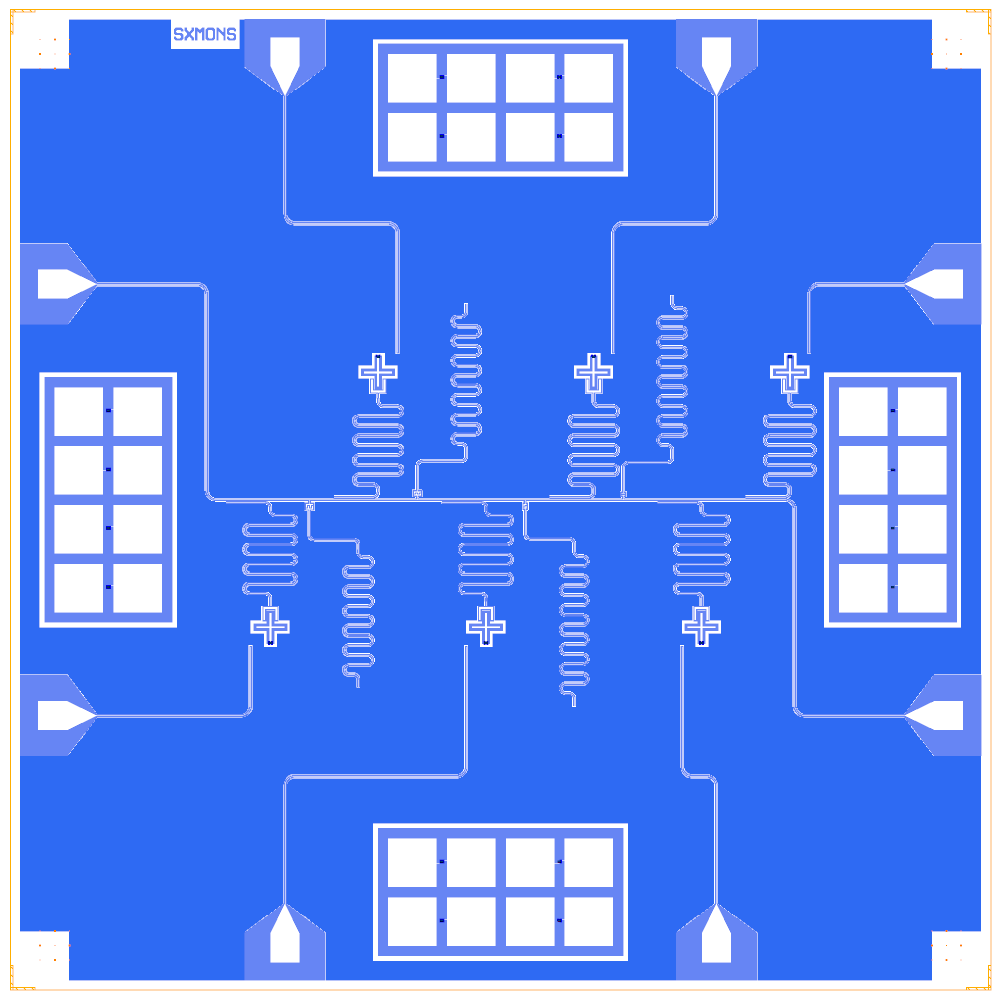

**On the chip so far:** 0 pads · 0 qubits · 18 other components · 21 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/singlexmons/4_routes.png')

In [12]:
for i, n in enumerate(qpos):
    d.sim_group(f"{n}_RR{i}", [n, f"RR{i}"], margin_um=300, analyses=["q3d_cmatrix", "eigenmode_epr"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "singlexmons.json")
display(Markdown(same))
print(d, "→", DESIGN)
print({k: round(v, 1) for k, v in d.result.route_lengths().items() if k.startswith(("RR", "TR"))})
layout_step(d, STEPS / "4_routes.png", **CHIP)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

**Errors** make the build unfit for fab, **warnings** are notes to read, **PDK design warnings** (`pad_edge`,
`pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside the PDK margins and are never enforced. `pdk_rn` judges the
device R_n (a SQUID's two junctions in parallel: 45 kΩ here, inside the window). Expected (from the v1 run): the 12 `dangling_port` warnings are
couplers 0 and 2 of each Swissmon: zero length (`cpl_length=[0, 140, 0]`) and unused, as in KQC.

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

Swissmon → island node (C and SQUID to ground) plus a coupler node for coupler 1 (C_g to the island, C to
ground). Each readout route → a λ/4 `TLres` at the coupler node plus a `HANGER` κ element to the feedline node.
The charge lines are drive controls; the test resonators are λ/4 `TLres` from the capacitors' far ports; the
launchers WN and ES are the feedline's 50 Ω ports.

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**QB0 and RR0 ports → nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(("QB0.", "RR0")))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

The six qubit / readout pairs share only the feedline, so each pair is its own sub-circuit
(`d.lom(select=[qubit, resonator])`, the feedline kept as a 25 Ω load): QuCat normal modes and κ, then the
QuTiP-dressed f_q, α, f_r and χ. From the v1 run: with the PDK SQUIDs f_q ≈ 6.5 GHz (KQC's assumed 16 nH gave ≈ 4.5 GHz), now
**above** the ≈ 5.2–5.7 GHz readouts: the qubits and readouts swap order, so χ changes sign compared with the
source. The test resonators are listed with their bare λ/4 frequency.

In [ ]:
pairs = {f"{n}+RR{i}": [n, f"RR{i}"] for i, n in enumerate(qpos)}
results = simulate_groups(d, pairs)
display(Markdown(groups_md(results)))
display(Markdown("**QB0 + RR0 normal modes (QuCat):**\n\n" + modes_md(results["QB0+RR0"])))
display(Markdown("| test resonator | length (µm) | bare f (GHz) |\n|---|---|---|\n" + "\n".join(
    f"| {n} | {b.value['length_um']:.0f} | {b.value['f_GHz']:.4f} |"
    for n, b in lb.model.branches.items() if n.startswith("TR"))))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) the two modes of each qubit–readout pair (QuCat; circles are qubits, squares the
readouts; filled markers are the QuTiP dressed values), (b) the dispersive shift |χ| of each readout. In the v1 run
the qubits sit ≈ 0.9–1.4 GHz above their readouts, and |χ| falls from RR0 to RR5 as the readouts move down.

In [ ]:
plot_lom(results, STEPS / "lom.png", title="singlexmons: LOM per qubit–readout pair")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The readout's coupling to the feedline is set by the hanger section: shorten RR0's coupler from 450 to 300 µm,
keeping its end under the qubit (its centre moves from x0 − 225 to x0 − 150).
The coupled-line κ drops (roughly with the square of the coupled length), f_r moves a little (the coupler is part
of the λ/4 line) and χ barely changes. Done on a copy (`design_copy`), so `singlexmons.json` keeps KQC's 450 µm.

In [ ]:
d2 = design_copy(DESIGN)
x0 = qpos["QB0"][0]                              # the coupler's far end stays under the qubit (x0)
d2["RR0"].set(to=dict(d2["RR0"].spec["to"], length=300, near=[x0 - 150, 5000]))
after = simulate_groups(d2, {"QB0+RR0": pairs["QB0+RR0"]})
display(Markdown("**RR0 hanger coupler: 450 → 300 µm**\n\n" + params_delta_md({"QB0+RR0": results["QB0+RR0"]}, after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/kqc/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

Per sim group a Q3D C-matrix job and an eigenmode / EPR job (every line leaving the box ends in a port, the
junction is a lumped port; the ground grid is removed — simulation exports never have cheese). `FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. CLI: `qcc sim run build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/kqc/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per sim group
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")   # the groups' second analysis
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

Per qubit–readout group: the island, coupler 1 and the charge line the box cuts as named nets (each named after its
LOM node, so the matrix goes straight into the circuit, Results 3). `fem_stage` solves each job with `RUN_FEM`, else
loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same six boxes in HFSS eigenmode: the SQUID is a lumped L_J ‖ C_J sheet, the feedline and the charge line leave
each box in 50 Ω, so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never KQC's
`run_pyepr_t1_estimate.py`) turns the junction's participation into dressed frequencies, α and χ. Six eigenmode
solves take a while; `RUN_FEM = {"q3d_cmatrix"}` solves only the Q3D jobs.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives S21 along the feedline through the `QB0_RR0` box, where RR0's hanger shows up as a notch. The
library cannot hand the solved eigenmode **mesh** itself to a driven setup (no such option yet), so
`driven_from_eigenmode` does the nearest honest thing: the same sim group and box, the eigenmode job's mesh seeds, the
adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast sweep
around it.

In [ ]:
f_drv = results["QB0+RR0"].params.get("RR0.f_GHz")   # the LOM's RR0 frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "QB0_RR0", jobs_eig["QB0_RR0"][0], keep_eig["QB0_RR0"], f_guess=f_drv)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["QB0_RR0"]:
    display(Markdown(driven_md(keep_drv["QB0_RR0"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: a qubit; ≈ 0: a resonator), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
lom_f = {}                                       # the LOM's f_q and f_r per pair (LOM 1)
for i in range(6):
    p = results[f"QB{i}+RR{i}"].params
    lom_f.update({f"QB{i}": p.get(f"QB{i}.f_q_GHz"), f"RR{i}": p.get(f"RR{i}.f_GHz")})
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

Each eigenmode job in the LOM's terms: the qubit's mode is the one its SQUID participates in most, the readout's the
remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms, κ = f/Q of
the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds RR0's notch.

In [ ]:
fem_values = {}
for i in range(6):
    keep = keep_eig.get(f"QB{i}_RR{i}")
    if keep:
        fem_values[f"QB{i}"] = epr_values(keep, {f"QB{i}": f"RR{i}"}, {f"RR{i}": lom_f[f"RR{i}"]})
if keep_drv["QB0_RR0"]:
    fem_values.setdefault("QB0", {}).update({f"driven {k}": x for k, x in
                                             driven_values(keep_drv["QB0_RR0"], "RR0", f_drv).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {x:.5g} |" for vals in fem_values.values() for k, x in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r, χ and κ of each pair from "
          "pyEPR, and RR0's S21 notch.")

## Results 3 · FEM against the LOM

Two comparisons per pair. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
for i in range(6):
    g, est = f"QB{i}+RR{i}", results[f"QB{i}+RR{i}"].params
    keys = [f"QB{i}.f_q_GHz", f"QB{i}.alpha_MHz", f"RR{i}.f_GHz", f"RR{i}.chi_MHz", f"RR{i}.kappa_MHz"]
    if keep_q3d.get(f"QB{i}_RR{i}"):
        on_fem = simulate(fill(d.lom(select=pairs[g]).model, DESIGN, keep_q3d[f"QB{i}_RR{i}"]), max_modes=2).params
        rows += [(key, est.get(key), on_fem.get(key), "LOM on the Q3D C-matrix") for key in keys]
    rows += [(key, est.get(key), fem_values[f"QB{i}"][key], "eigenmode + pyEPR") for key in keys
             if key in fem_values.get(f"QB{i}", {})]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

KQC's `SingleXmons` states no frequencies, so this notebook sets one as an exercise: **QB0 at 6.30 GHz**, ≈ 0.24 GHz
below where the LOM puts it (from the v1 run: 6.542 GHz, its readout RR0 at 5.655 GHz), so the qubit moves closer to
its readout and |χ| grows. It is reachable inside the PDK junction window: L_J goes from 6.73 nH to ≈ 7.24 nH,
R_n ≈ 48 kΩ (`pdk_lj_bounds` keeps the feedback within 40–50 kΩ). The readouts are not targeted. The hanger readouts
make a standard qubit–readout pair for the estimators.

The targets go on a copy (`target_copy` → `build/singlexmons_target.json`), so the design file keeps its own (none).
`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — on the Q3D values where a solve was kept — and picks one value per quantity (the consensus).
`loop.feedback` anchors a surrogate on that point and proposes the knobs that put the target inside its tolerance
(f_q ± 20 MHz); the proposal is written as revision 1, built and netlist-checked. The revision changes the LOM's
L_J; the drawn SQUID keeps its 0.25 µm straight fingers until it is sized again with
`trilayer_junction(..., lj_nH=..., squid=True)`. If the consensus table is empty, `loop.analyse` found no
qubit–readout pair it can tune here (see the log's requests): the cell then says so instead of proposing knobs.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"QB0": {"f_q_GHz": 6.30}}   # the exercise target (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
the target is inside its tolerance or `MAX_ITER` revisions are made (`build/singlexmons/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` each revision's QB0_RR0 Q3D job is exported and solved first (`solve_rev`), so the
loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's value against the target
and the knob it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D component jobs, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ('QB0_RR0',)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

`singlexmons.json` is the design: `qcc build examples/designs/kqc/singlexmons.json` writes `build/singlexmons.oas`
+ sidecar. `export_fab` writes the PDK fab layers: 1/0 base etch with the cheese (source `build`: KQC's grid),
the filled 3/0 keep-out (route + 10 µm, component + 24 µm, plus every grid hole), the trilayer layers 2/0 + 4/0 + 50–53/0, airbridges 300/301 if any, and the frame
100/0, 1000/0, 1001/0. `qcc mask examples/designs/kqc/singlexmons.json` writes the complete file (with corner
rounding; `FULL_FAB` here).

For simulation, `build_simulation(..., airbridges=True)` keeps airbridges (default: dropped), and the cheese is
never exported (`setup.geometry` reports what was left out).

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "QB0_RR0", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Fab 2 · Snapshots

Full chip; QB0 with its coupler; the QB0 SQUID; the RR0 hanger coupler along the feedline (5 µm ground strip);
the die frame's south-west corner; QB0 in the **fab view** (the mask from Fab 1: 1/0 with KQC's grid holes, 3/0,
the trilayer layers); and KQC's own `SingleXmons` built stand-alone for comparison. (At full-chip scale KQC's grid fills the ground as one tone; the zooms and the fab view show the holes.)

In [ ]:
show_snapshot(d, OUT / "singlexmons.png")
x, y, _ = qpos["QB0"]
show_snapshot(d, OUT / "singlexmons_qb0.png", box=(x - 300, y - 300, x + 300, y + 300), width=420)
show_snapshot(d, OUT / "singlexmons_squid.png", box=(x - 50, y + 100, x + 50, y + 200), width=360)
show_snapshot(d, OUT / "singlexmons_coupler.png", box=(x - 450, y - 1340, x - 150, y - 1240), size=(1800, 600), width=540)
show_snapshot(d, OUT / "singlexmons_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "singlexmons_fab.oas", OUT / "singlexmons_fab_qb0.png", box=(x - 250, y - 250, x + 250, y + 250),
          size=(1200, 1200), width=420);

In [ ]:
from kqcircuits.chips.single_xmons import SingleXmons
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
top = ref.create_cell("kqc_singlexmons")
top.insert(pya.DCellInstArray(SingleXmons.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "singlexmons_kqc_original.oas"))
snap_file(Path("build") / "singlexmons_kqc_original.oas", OUT / "singlexmons_kqc.png", box=(-100, -100, 10100, 10100),
          width=420);

## Summary

| | |
|---|---|
| **matches the source** | the six Swissmons, tees, capacitors, test resonators, junction-test arrays at KQC's positions with KQC's parameters; the feedline path; readout lengths and the 27 µm coupling at KQC's coupler centres; charge lines; KQC's whole-area ground grid |
| **differs (PDK)** | Quantcore die frame; launchers 80 µm further in (outer etch 100 µm from the edge, `frame.pad_edge`); sapphire; trilayer SQUIDs (f_q ≈ 6.5 GHz, above the readouts); hanger couplers anchored by `near=`, corners by the launcher ports |
| **simplified** | readout meander before the coupler; router-fitted test-resonator meanders |
| **PDK design warnings** | as listed in Check 1 (the SQUIDs' device R_n, 45 kΩ, is inside the window) |
| **FEM** | 13 jobs (6 × Q3D, 6 × eigenmode/EPR, the QB0_RR0 driven run) exported to `build/jobs/singlexmons_*`, not solved here |
| layout | built in eight segments (die and launchers, the launcher check, the feedline with the test resonators, the qubits with the junction-test arrays, the readouts; no coupling; the charge lines; the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (QB0 6.30 GHz): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells; the revision's drawn SQUID keeps its fingers (size it with `trilayer_junction`) |